# Pretraining — do the unlabelled samples make the graph model better?

Of the 116,656 QC-passed samples, 14,033 sit in a disease cohort. Nothing so far has
used the other ~102,600. Here a GraphSAGE encoder learns from them **without any label**,
by *masked edge reconstruction*. Some of each sample's taxon links are hidden, and the
model has to say which taxa the sample carries and how abundant they are. The pretrained
encoder then starts the disease model of Experiment B, and is compared with the same model
started from random weights, on the same folds and seeds.

**Population: unlabelled samples only.** Every sample in any disease cohort is left out of
pretraining, so no sample the disease models are later tested on ever reaches the encoder,
not even without its label. Pretraining on all samples would let the encoder see the
held-out studies' microbiomes before the test.

**The risk, stated in advance.** The pretraining samples come from over 300 studies, and
"which study is this" is the strongest pattern in the data (the variance analysis). An
encoder that learns to reconstruct composition may mostly learn study identity, which would
make leave-one-project-out *worse*. Section 4 measures this directly.

| variant | what it is |
|---|---|
| GraphSAGE, G1 (Experiment B) | random start, 60 epochs: the reference |
| **pretrained, fine-tuned** | pretrained start, the whole model trained 60 epochs on the disease |
| **pretrained, frozen** | pretrained encoder kept fixed; only the final layer (129 weights) learns |

**When does pretraining help?** Its leave-one-project-out AUC must beat the
random-start GraphSAGE by more than the fold-to-fold sd: the same bar as Experiment B,
stated here before the results.

Outputs: `data/processed/gae_encoder.pt` (the encoder, gitignored),
`reports/graph_pretrain_history.csv`, `reports/graph_pretrain_cv.csv`,
`reports/graph_pretrain_summary.csv`, `reports/figures/phase7_pretrain_curve.png`,
`reports/figures/phase7_pretrain_lopo.png`.

## Setup

In [1]:
import os
import sys
import time
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)  # worker processes import `src` too

from src import differential as diff
from src import gnn
from src import graph_disease as gd

REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
PROCESSED = ROOT / "data" / "processed"
RUN_DIR = PROCESSED / "graph_disease_runs"
CHECKPOINT = ROOT / gd.PRETRAINED_ENCODER

with open(ROOT / "config" / "params.yaml") as f:
    params = yaml.safe_load(f)
SEED = params["seed"]
gcfg = params["graph"]
pcfg = gcfg["pretrain"]
bcfg = gcfg["disease"]

import torch
import torch_geometric
warnings.filterwarnings("ignore")
torch.set_num_threads(pcfg["threads"])

print(f"seed={SEED}  torch={torch.__version__}  torch_geometric={torch_geometric.__version__}")
print(f"pretraining: {pcfg['epochs']} epochs, mask {pcfg['mask_frac']:.0%}, "
      f"{pcfg['neg_sampling_ratio']} negative per hidden edge, {pcfg['threads']} threads")
print(f"downstream: {pcfg['models']} x {bcfg['categories']} x seeds {bcfg['seeds']}")

C:\Users\Jadrovski\vnp\MicroWave\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


seed=42  torch=2.14.0+cpu  torch_geometric=2.8.1
pretraining: 20 epochs, mask 15%, 1 negative per hidden edge, 8 threads
downstream: ['sage_g1_pt_full', 'sage_g1_pt_frozen'] x ['IBD', 'HIV', 'NAFLD', 'T1D', 'asthma', 'cancer_other'] x seeds [42, 43, 44]


## 1 — The pretraining population

The G1 graph over every QC-passed sample outside the disease cohorts. Taxon statistics and
sample-feature scaling are computed on this population.

In [2]:
t0 = time.time()
graph, pt_samples, n_cohort = gd.pretraining_graph(ROOT, params)
cohort = pd.read_parquet(PROCESSED / "cohort_within_project.parquet")
assert not set(pt_samples) & set(diff.sample_keys(cohort)), "a cohort sample is in pretraining"
pt_projects = np.array([s.split("_")[0] for s in pt_samples])
print(f"{len(pt_samples):,} pretraining samples from {len(set(pt_projects))} studies; "
      f"{n_cohort:,} cohort samples left out")
print(f"{graph['sample', 'abundance', 'taxon'].num_edges:,} abundance edges  "
      f"[{time.time() - t0:.0f}s]")

102,623 pretraining samples from 313 studies; 14,033 cohort samples left out
5,628,093 abundance edges  [9s]


## 2 — Pretraining

Each epoch hides a fresh 15% of the training samples' abundance edges. For each hidden edge
the model must (a) tell it apart from an absent taxon of the same sample and (b) predict its
weight. 2% of the samples are held out for scoring: 15% of their edges are hidden for the
whole run and never trained on.

This is the expensive step, so the encoder is saved and re-used: if the checkpoint exists and
was made with the current settings, it is loaded instead of retrained.

In [3]:
enc_kw = dict(embed_dim=gcfg["taxon_embed_dim"],
              **{k: v for k, v in gcfg["models"]["graphsage"].items() if k != "aggr"})
run_cfg = dict(encoder_kwargs=enc_kw, epochs=pcfg["epochs"], batch_size=pcfg["batch_size"],
               lr=pcfg["lr"], weight_decay=gcfg["train"]["weight_decay"],
               mask_frac=pcfg["mask_frac"], neg_ratio=pcfg["neg_sampling_ratio"],
               neighbor_sampling=gcfg["neighbor_sampling"], eval_frac=pcfg["eval_frac"],
               seed=pcfg["seed"])

ckpt = torch.load(CHECKPOINT, weights_only=False) if CHECKPOINT.exists() else None
if ckpt is not None and ckpt["config"] == run_cfg and ckpt["n_samples"] == len(pt_samples):
    history, baselines = pd.DataFrame(ckpt["history"]), ckpt["baselines"]
    print(f"loaded {CHECKPOINT.name} (trained in {ckpt['minutes']:.0f} min)")
else:
    t0 = time.time()
    encoder, history, baselines = gnn.pretrain_graph_autoencoder(
        graph, log=lambda s: print(s, flush=True), **run_cfg)
    minutes = (time.time() - t0) / 60
    torch.save(dict(encoder=gnn.encoder_state(encoder), config=run_cfg,
                    n_samples=len(pt_samples), history=history.to_dict("list"),
                    baselines=baselines, minutes=minutes), CHECKPOINT)
    print(f"pretrained in {minutes:.0f} min, saved {CHECKPOINT.name}")
history.to_csv(REPORTS / "graph_pretrain_history.csv", index=False)

epoch  1/20  train loss 2.8664  held-out: loss 2.5275, existence AUC 0.896, weight MSE 2.117  [1.0 min]


epoch  2/20  train loss 2.4633  held-out: loss 2.3323, existence AUC 0.908, weight MSE 1.946  [1.0 min]


epoch  3/20  train loss 2.3414  held-out: loss 2.2243, existence AUC 0.911, weight MSE 1.845  [1.0 min]


epoch  4/20  train loss 2.2472  held-out: loss 2.1454, existence AUC 0.917, weight MSE 1.777  [1.2 min]


epoch  5/20  train loss 2.1921  held-out: loss 2.1353, existence AUC 0.917, weight MSE 1.769  [1.8 min]


epoch  6/20  train loss 2.1534  held-out: loss 2.0901, existence AUC 0.918, weight MSE 1.725  [1.9 min]


... (11 outputs left out)

epoch 18/20  train loss 2.0288  held-out: loss 1.9745, existence AUC 0.927, weight MSE 1.629  [2.8 min]


epoch 19/20  train loss 2.0332  held-out: loss 1.9886, existence AUC 0.925, weight MSE 1.638  [2.9 min]


epoch 20/20  train loss 2.0282  held-out: loss 1.9733, existence AUC 0.927, weight MSE 1.624  [3.4 min]


pretrained in 70 min, saved gae_encoder.pt


## 3 — Did it learn anything?

Scored on the held-out samples' hidden edges, beside two baselines that ignore the sample
entirely: a taxon's prevalence (how often it is present anywhere) for existence, and its
mean weight for the weight. An encoder that beats them has learned something about *this*
sample's composition from the rest of it.

In [4]:
last = history.iloc[-1]
recon = pd.DataFrame({
    "pretrained encoder": [last["eval_exist_auc"], last["eval_weight_mse"]],
    "sample-blind baseline": [baselines["exist_auc_prevalence"], baselines["weight_mse_taxon_mean"]],
}, index=["existence AUC (higher is better)", "weight MSE (lower is better)"])
recon["encoder better"] = [recon.iloc[0, 0] > recon.iloc[0, 1], recon.iloc[1, 0] < recon.iloc[1, 1]]
print(f"held out: {baselines['n_eval_samples']:,} samples, {baselines['n_eval_edges']:,} hidden edges")
recon.round(3)

held out: 2,052 samples, 16,871 hidden edges


,pretrained encoder,sample-blind baseline,encoder better
existence AUC (higher is better),0.927,0.868,True
weight MSE (lower is better),1.624,2.490,True


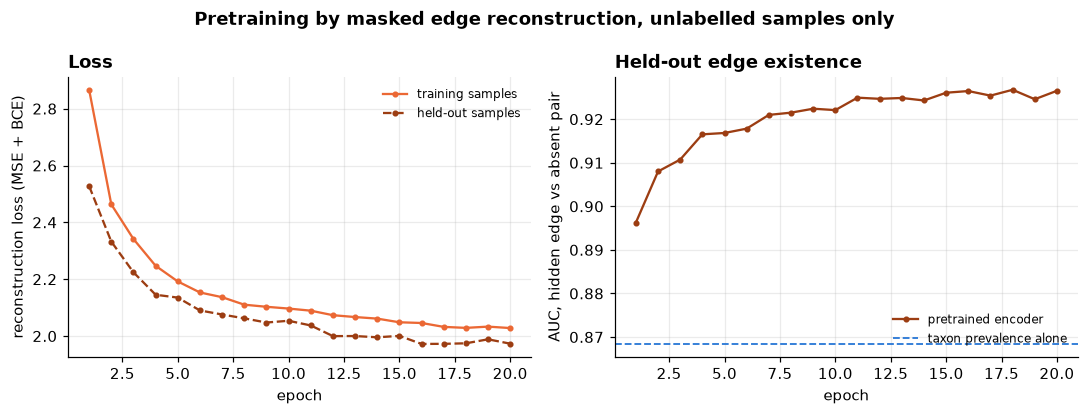

In [5]:
fig = gd.plot_pretrain_history(history, baselines)
fig.savefig(FIGURES / "phase7_pretrain_curve.png")

## 4 — Did it learn study identity?

For 5,000 random pretraining samples: the share of each sample's 10 nearest neighbours that
come from its own study, in three spaces. These are the CLR composition itself (Aitchison
distance), the same encoder with random weights, and the pretrained encoder. If pretraining
pushes this share above the CLR one, the encoder has organised samples by study more than
the raw data already does. That is the risk named at the top. Chance is the share expected
if neighbours were random.

In [6]:
rng = np.random.default_rng(SEED)
probe = np.sort(rng.choice(len(pt_samples), 5000, replace=False))
groups = pt_projects[probe]
probe_keys = [pt_samples[i] for i in probe]
clr_probe, _ = diff.load_clr(PROCESSED / "abund_clr.parquet", probe_keys)
clr_probe = clr_probe.loc[probe_keys].to_numpy()

state = torch.load(CHECKPOINT, weights_only=False)["encoder"]
torch.manual_seed(pcfg["seed"])
random_enc = gnn.HeteroSAGE(graph, 1, **enc_kw)
gnn.embed_samples(random_enc, graph, probe[:8], neighbor_sampling=gcfg["neighbor_sampling"])
pre_enc = gnn.load_pretrained(gnn.HeteroSAGE(graph, 1, **enc_kw), state, frozen=True)

sizes = pd.Series(groups).value_counts().to_numpy()
spaces = {
    "CLR composition": clr_probe,
    "encoder, random weights": gnn.embed_samples(random_enc, graph, probe,
                                                 neighbor_sampling=gcfg["neighbor_sampling"]),
    "encoder, pretrained": gnn.embed_samples(pre_enc, graph, probe,
                                             neighbor_sampling=gcfg["neighbor_sampling"]),
}
same_study = pd.Series({name: gnn.same_group_neighbour_rate(x, groups, k=10)
                        for name, x in spaces.items()}, name="same-study share of 10 neighbours")
same_study["chance"] = float((sizes * (sizes - 1)).sum() / (len(groups) * (len(groups) - 1)))
same_study.round(3).to_frame()

,same-study share of 10 neighbours
CLR composition,0.300
"encoder, random weights",0.239
"encoder, pretrained",0.255
chance,0.011


## 5 — The disease runs

The two pretrained variants, for every disease and seed. They use the same folds, epochs and
inductive protocol as GraphSAGE in Experiment B, whose finished runs are the reference.
Jobs write to the same run directory and are skipped once done.

In [7]:
jobs = [(cat, m, s) for cat in bcfg["categories"] for m in pcfg["models"] for s in bcfg["seeds"]]
ref_jobs = [(cat, "sage_g1", s) for cat in bcfg["categories"] for s in bcfg["seeds"]]
missing_ref = [j for j in ref_jobs if not gd.run_path(RUN_DIR, *j).exists()]
assert not missing_ref, f"Experiment B runs missing: {missing_ref}"

order = {"IBD": 0, "cancer_other": 1, "HIV": 2, "asthma": 3, "NAFLD": 4, "T1D": 5}
todo = sorted((j for j in jobs if not gd.run_path(RUN_DIR, *j).exists()),
              key=lambda j: order.get(j[0], 9))
print(f"{len(jobs) - len(todo)} of {len(jobs)} jobs already done; running {len(todo)}")

t_all = time.time()
if todo:
    with ProcessPoolExecutor(max_workers=bcfg["parallel_jobs"]) as pool:
        futures = {pool.submit(gd.run_job_to_file, str(ROOT), params, cat, m, s, str(RUN_DIR),
                               bcfg["threads_per_job"]): (cat, m, s) for cat, m, s in todo}
        for fut in as_completed(futures):
            cat, m, s = futures[fut]
            path, minutes = fut.result()
            res = pd.read_csv(path).groupby("cv_scheme")["auc"].mean()
            print(f"{cat:12s} {m:17s} seed {s}: LOPO AUC {res.get('leave_project_out', np.nan):.3f}  "
                  f"random AUC {res.get('random_kfold', np.nan):.3f}  [{minutes:.1f} min]", flush=True)
print(f"all jobs done in {(time.time() - t_all) / 60:.0f} min")

0 of 36 jobs already done; running 36


IBD          sage_g1_pt_full   seed 43: LOPO AUC 0.735  random AUC 0.808  [5.1 min]


IBD          sage_g1_pt_full   seed 42: LOPO AUC 0.735  random AUC 0.810  [5.1 min]


IBD          sage_g1_pt_full   seed 44: LOPO AUC 0.739  random AUC 0.815  [5.1 min]


IBD          sage_g1_pt_frozen seed 42: LOPO AUC 0.715  random AUC 0.755  [4.6 min]


IBD          sage_g1_pt_frozen seed 43: LOPO AUC 0.719  random AUC 0.753  [4.6 min]


... (28 outputs left out)

T1D          sage_g1_pt_frozen seed 42: LOPO AUC 0.449  random AUC 0.560  [0.7 min]


T1D          sage_g1_pt_frozen seed 43: LOPO AUC 0.462  random AUC 0.532  [0.7 min]


T1D          sage_g1_pt_frozen seed 44: LOPO AUC 0.444  random AUC 0.554  [0.7 min]


all jobs done in 30 min


## 6 — With vs without pretraining

AUC averaged over folds, then over seeds, as in Experiment B. The flat baselines and the
SAGE-sized MLP are Experiment B's rows, for context.

In [8]:
read = lambda j: pd.read_csv(gd.run_path(RUN_DIR, *j), keep_default_na=False, na_values=[""])
rows = pd.concat([read(j) for j in jobs + ref_jobs], ignore_index=True)
rows.loc[rows["model"].isin(pcfg["models"])].to_csv(REPORTS / "graph_pretrain_cv.csv", index=False)

per_seed = (rows.groupby(["disease_category", "model", "cv_scheme", "seed"])["auc"]
            .agg(auc="mean", fold_sd="std").reset_index())
summary = (per_seed.groupby(["disease_category", "model", "cv_scheme"])
           .agg(auc_mean=("auc", "mean"), auc_seed_sd=("auc", "std"), fold_sd=("fold_sd", "mean"))
           .reset_index())
summary[summary["model"].isin(pcfg["models"])].to_csv(REPORTS / "graph_pretrain_summary.csv",
                                                      index=False)
context = pd.read_csv(REPORTS / "graph_disease_summary.csv")
context = context[context["model"].isin(["logreg", "gboost", "mlp_sage"])]
both = pd.concat([context, summary], ignore_index=True)
(both.pivot_table(index=["disease_category", "model"], columns="cv_scheme", values="auc_mean")
 .reindex([m for m in gd.ORDER if m in set(both["model"])], level="model").round(3))

cv_scheme                           leave_project_out  random_kfold
disease_category model                                             
HIV              logreg                         0.542         0.680
                 gboost                         0.532         0.775
                 mlp_sage                       0.549         0.721
                 sage_g1                        0.516         0.760
                 sage_g1_pt_full                0.545         0.726
                 sage_g1_pt_frozen              0.540         0.732
IBD              logreg                         0.701         0.747
                 gboost                         0.728         0.820
                 mlp_sage                       0.739         0.835
                 sage_g1                        0.693         0.795
                 sage_g1_pt_full                0.736         0.811
                 sage_g1_pt_frozen              0.720         0.754
NAFLD            logreg                         0.626         0.761
                 gboost                         0.673         0.757
                 mlp_sage                       0.694         0.790
                 sage_g1                        0.707         0.768
                 sage_g1_pt_full                0.653         0.739
                 sage_g1_pt_frozen              0.651         0.737
T1D              logreg                         0.401         0.614
                 gboost                         0.480         0.579
                 mlp_sage                       0.400         0.641
                 sage_g1                        0.402         0.559
                 sage_g1_pt_full                0.408         0.631
                 sage_g1_pt_frozen              0.452         0.549
asthma           logreg                         0.588         0.598
                 gboost                         0.545         0.606
                 mlp_sage                       0.628         0.634
                 sage_g1                        0.536         0.528
                 sage_g1_pt_full                0.591         0.565
                 sage_g1_pt_frozen              0.527         0.495
cancer_other     logreg                         0.595         0.640
                 gboost                         0.577         0.718
                 mlp_sage                       0.576         0.676
                 sage_g1                        0.522         0.667
                 sage_g1_pt_full                0.592         0.674
                 sage_g1_pt_frozen              0.561         0.636

### The pre-stated test

Pretrained minus random-start GraphSAGE, leave-one-project-out, paired by seed, against the
random-start model's fold-to-fold sd.

In [9]:
lopo = per_seed[per_seed["cv_scheme"] == "leave_project_out"]
wide = lopo.pivot_table(index=["disease_category", "seed"], columns="model", values="auc")
ref_sd = (summary[(summary["model"] == "sage_g1") & (summary["cv_scheme"] == "leave_project_out")]
          .set_index("disease_category")["fold_sd"])
verdicts = []
for cat in bcfg["categories"]:
    for m in pcfg["models"]:
        delta = wide.loc[cat, m] - wide.loc[cat, "sage_g1"]
        sd = ref_sd[cat]
        verdicts.append(dict(disease_category=cat, model=m,
                             auc_random_start=wide.loc[cat, "sage_g1"].mean(),
                             auc_pretrained=wide.loc[cat, m].mean(),
                             delta=delta.mean(), delta_seed_sd=delta.std(), fold_sd=sd,
                             verdict="helps" if delta.mean() > sd else
                                     ("hurts" if delta.mean() < -sd else "within fold noise")))
verdicts = pd.DataFrame(verdicts)
verdicts.round(3)

,disease_category,model,auc_random_start,auc_pretrained,delta,delta_seed_sd,fold_sd,verdict
0,IBD,sage_g1_pt_full,0.693,0.736,0.043,0.010,0.147,within fold noise
1,IBD,sage_g1_pt_frozen,0.693,0.720,0.027,0.012,0.147,within fold noise
2,HIV,sage_g1_pt_full,0.516,0.545,0.029,0.015,0.111,within fold noise
3,HIV,sage_g1_pt_frozen,0.516,0.540,0.024,0.028,0.111,within fold noise
4,NAFLD,sage_g1_pt_full,0.707,0.653,-0.054,0.005,0.075,within fold noise
5,NAFLD,sage_g1_pt_frozen,0.707,0.651,-0.056,0.002,0.075,within fold noise
6,T1D,sage_g1_pt_full,0.402,0.408,0.006,0.014,0.058,within fold noise
7,T1D,sage_g1_pt_frozen,0.402,0.452,0.050,0.011,0.058,within fold noise
8,asthma,sage_g1_pt_full,0.536,0.591,0.054,0.010,0.026,helps
9,asthma,sage_g1_pt_frozen,0.536,0.527,-0.009,0.018,0.026,within fold noise


### Does pretraining change how much a shared-study split flatters the model?

Random k-fold AUC minus leave-one-project-out AUC per model. Experiment C called this gap
batch-leakage inflation. If pretraining mainly taught the encoder study identity, this gap
would grow.

In [10]:
gap = summary.pivot_table(index=["disease_category", "model"], columns="cv_scheme", values="auc_mean")
gap = (gap["random_kfold"] - gap["leave_project_out"]).rename("random minus LOPO").unstack("model")
gap[["sage_g1", *pcfg["models"]]].round(3)

model,sage_g1,sage_g1_pt_full,sage_g1_pt_frozen
disease_category,,,
HIV,0.244,0.182,0.192
IBD,0.102,0.075,0.034
NAFLD,0.061,0.086,0.085
T1D,0.157,0.223,0.097
asthma,-0.008,-0.026,-0.032
cancer_other,0.145,0.082,0.075


## 7 — Figure

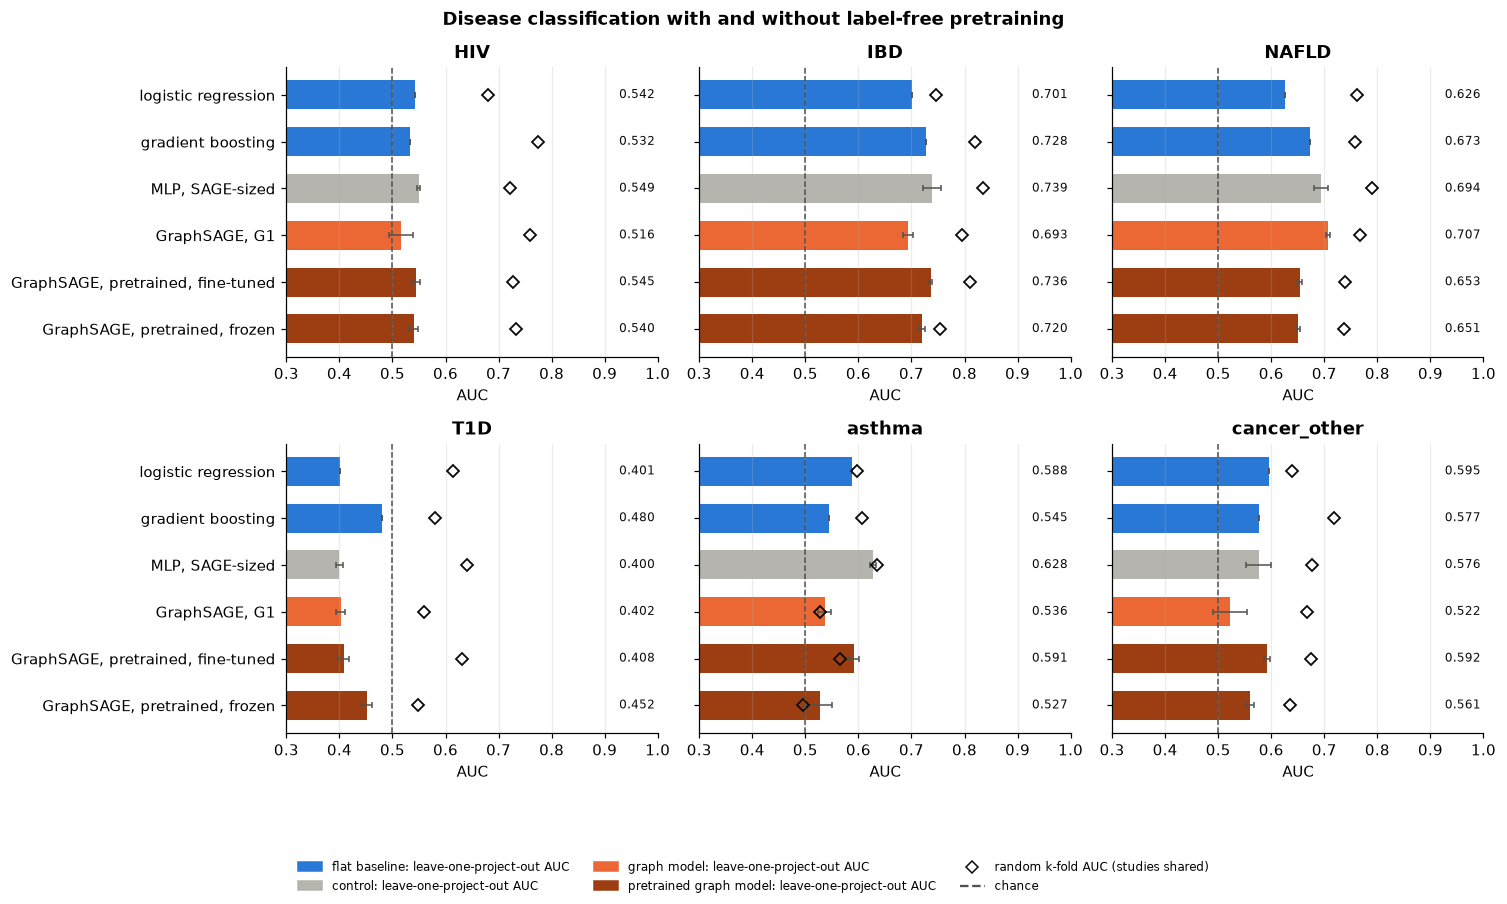

In [11]:
fig = gd.plot_disease_lopo(both[both["disease_category"].isin(bcfg["categories"])],
                           title="Disease classification with and without label-free pretraining")
fig.savefig(FIGURES / "phase7_pretrain_lopo.png")